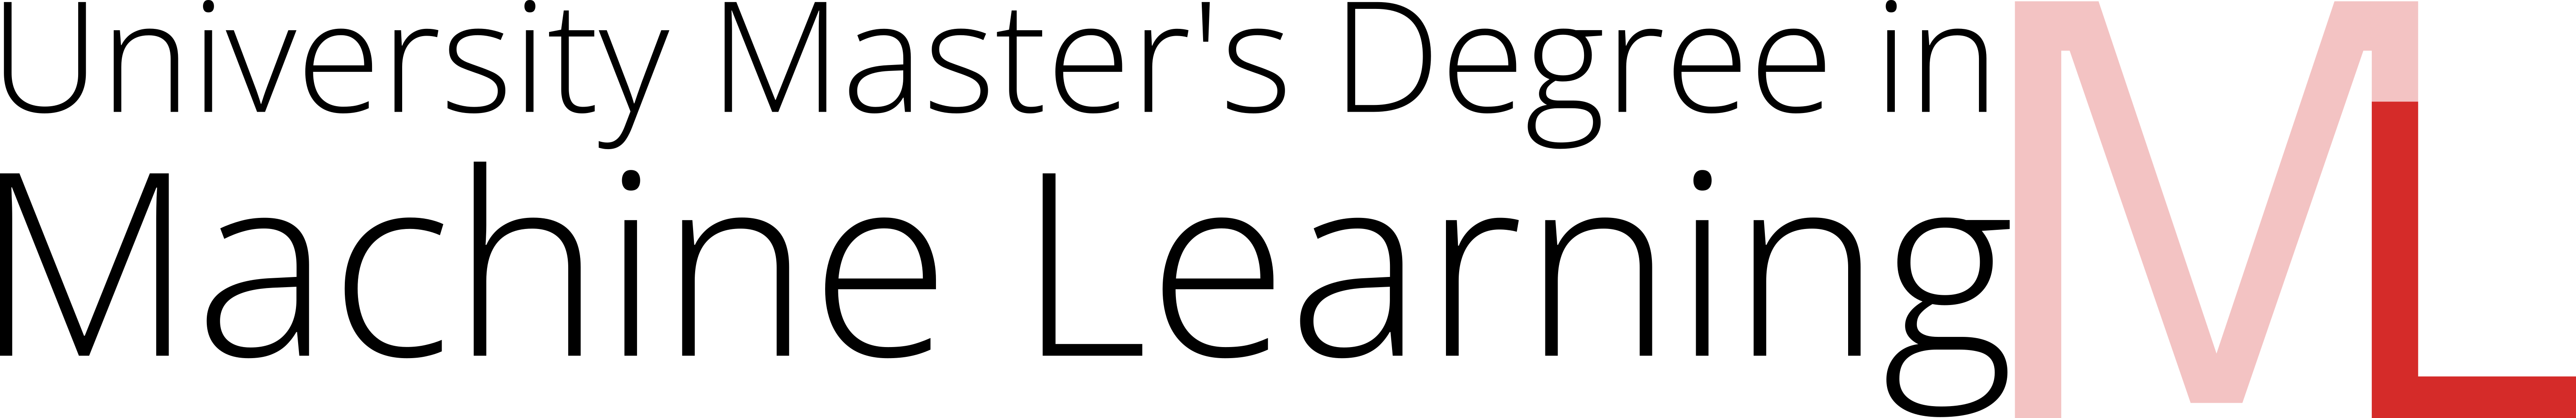

In this lab, we will become familiar with the concept of convolution before moving on to defining our own trainable convolutions. Once we have covered these two concepts, we will be able to define a convolutional layer, which we will later use as a low-level feature extractor.


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as f
from matplotlib import pyplot as plt
from torchvision import transforms
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

## Image convolution from scratch

Implement a  that performs a simple **2D convolution operation** between an input matrix `X` (representing a grayscale image) and a kernel `K` (filter).

The function should:

- Take as input two **PyTorch tensors**:

   * `X`: a 2D tensor of size `(n_h, n_w)`
   * `K`: a 2D tensor of size `(k_h, k_w)`
- For each valid position `(i, j)` in the input matrix, compute the sum of element-wise multiplications between the kernel and the corresponding region of `X`.

**Hint**: There are at least two possible strategies to implement the iteration:

- You may start at the top-left corner (0,0) and select submatrices that extend to the right and downward.

- Alternatively, for odd-sized kernels (e.g., a 3×3 kernel), you may center the kernel on a pixel position (e.g., (1,1) for the top-left valid center) and then expand upward/downward and left/right to cover the full region.



In [2]:
def convolution(X, K):
    n_h, n_w = X.shape
    k_h, k_w = K.shape

    # Dimensiones exactas de la matriz de salida (modo 'valid')
    out_h = n_h - k_h + 1
    out_w = n_w - k_w + 1

    result_matrix = torch.zeros((out_h, out_w))

    # Iteración desde la esquina superior izquierda de cada ventana
    for i in range(out_h):
        for j in range(out_w):
            window = X[i : i + k_h, j : j + k_w]
            result_matrix[i, j] = (window * K).sum()

    return result_matrix

Take any image (not very large), define a possible kernel and test the funcion.

In [3]:
K = torch.tensor(([-1,0,1],[-2,0,2],[-1,0,1]))

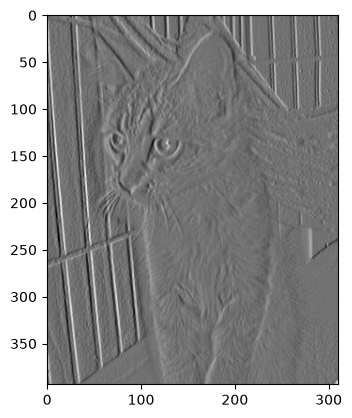

In [4]:
imagen = plt.imread('cat_dog_small/train/cat/cat.2.jpg').copy()
t = transforms.Compose([transforms.ToTensor(),
                        transforms.Grayscale(),
                        transforms.Lambda(lambda x:x.squeeze())])
imagen = t(imagen)
plt.imshow(imagen.numpy(), cmap='gray')

convol = convolution(imagen, K)

plt.imshow(convol.numpy(), cmap='gray')


Modify your convolution implementation to support **symmetric zero-padding** with a single parameter. Implement a Python function `convolution(X, K, p)` that performs a **2D convolution** between an input matrix `X` (representing a grayscale image) and a kernel `K` (filter), using the same amount of padding in both height and width.

The function should take as input:

   * `X`: a 2D **PyTorch tensor** of size `(n_h, n_w)`
   * `K`: a 2D **PyTorch tensor** of size `(k_h, k_w)`
   * `p`: an integer specifying the amount of zero-padding applied equally in both directions (top/bottom and left/right).

The function should create an auxiliary matrix filled with zeros, and copy the original image into the center of this matrix, so that convolution can be computed over the padded input.

In [5]:
def convolution(X, K, p):
    n_h, n_w = X.shape
    k_h, k_w = K.shape

    # 1. Crear matriz auxilar con zero-padding alrededor de X
    X_padded = torch.zeros((n_h + 2 * p, n_w + 2 * p), dtype=X.dtype, device=X.device)
    
    # 2. Copiar la imagen original en el centro de la matriz con padding
    if p > 0:
        X_padded[p:-p, p:-p] = X
    else:
        X_padded = X

    # 3. Calcular las dimensiones de la matriz de salida
    out_h = (n_h + 2 * p) - k_h + 1
    out_w = (n_w + 2 * p) - k_w + 1

    result_matrix = torch.zeros((out_h, out_w), dtype=X.dtype, device=X.device)

    # 4. Realizar la convolución sobre la matriz con padding
    for i in range(out_h):
        for j in range(out_w):
            window = X_padded[i : i + k_h, j : j + k_w]
            result_matrix[i, j] = (window * K).sum()

    return result_matrix

(396, 312, 3)
torch.Size([454, 370])


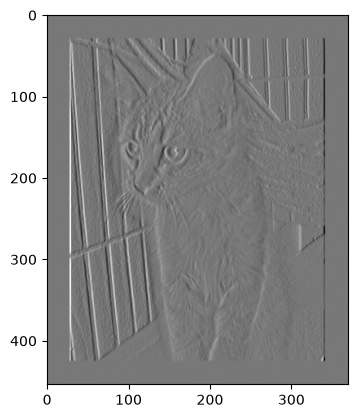

In [6]:
imagen = plt.imread('cat_dog_small/train/cat/cat.2.jpg').copy()
t = transforms.Compose([transforms.ToTensor(),
                        transforms.Grayscale(),
                        transforms.Lambda(lambda x:x.squeeze())])
print(imagen.shape)
imagen = t(imagen)
plt.imshow(imagen.numpy(), cmap='gray')

convol = convolution(imagen, K, 30)

plt.imshow(convol.numpy(), cmap='gray')
print(convol.shape)

Extend your convolution implementation to support both **zero-padding** and **stride**. Implement a Python function `convolution(X, K, p, s)` that performs a **2D convolution** between an input matrix `X` (representing a grayscale image) and a kernel `K` (filter), with padding `p` and stride `s`.

The function should take as input:

   * `X`: a 2D **PyTorch tensor** of size `(n_h, n_w)`
   * `K`: a 2D **PyTorch tensor** of size `(k_h, k_w)`
   * `p`: an integer specifying the amount of zero-padding applied equally to all sides of the input
   * `s`: an integer specifying the stride, i.e., the step size when moving the kernel horizontally and vertically.


In [7]:
def convolution(X, K, p, s):
    n_h, n_w = X.shape
    k_h, k_w = K.shape

    # 1. Crear matriz auxiliar con zero-padding alrededor de X
    X_padded = torch.zeros((n_h + 2 * p, n_w + 2 * p), dtype=X.dtype, device=X.device)
    
    # 2. Copiar la imagen original en el centro
    if p > 0:
        X_padded[p:-p, p:-p] = X
    else:
        X_padded = X

    # 3. Calcular dimensiones de salida con padding y stride
    out_h = (n_h + 2 * p - k_h) // s + 1
    out_w = (n_w + 2 * p - k_w) // s + 1

    result_matrix = torch.zeros((out_h, out_w), dtype=X.dtype, device=X.device)

    # 4. Convolución aplicando el desplazamiento mediante el stride
    for i in range(out_h):
        for j in range(out_w):
            # i * s y j * s determinan la esquina superior izquierda de la ventana
            window = X_padded[i * s : i * s + k_h, j * s : j * s + k_w]
            result_matrix[i, j] = (window * K).sum()

    return result_matrix

(396, 312, 3)
torch.Size([152, 124])


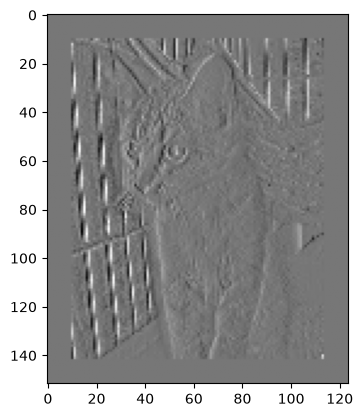

In [8]:
imagen = plt.imread('cat_dog_small/train/cat/cat.2.jpg').copy()
t = transforms.Compose([transforms.ToTensor(),
                        transforms.Grayscale(),
                        transforms.Lambda(lambda x:x.squeeze())])
print(imagen.shape)
imagen = t(imagen)
plt.imshow(imagen.numpy(), cmap='gray')

convol = convolution(imagen, K, 30, 3)

plt.imshow(convol.numpy(), cmap='gray')
print(convol.shape)

Instead of manually implementing the convolution with loops and element-wise operations, PyTorch provides a convenient way to perform 2D convolution using `torch.nn.functional`. The function `torch.nn.functional.conv2d` can be used to apply a kernel to an input tensor efficiently.

To implement the same convolution with **symmetric padding**, you need to:

1. **Add batch and channel dimensions** to your input and kernel, because `conv2d` expects inputs of shape `(batch_size, channels, height, width)` and kernels of shape `(out_channels, in_channels, k_h, k_w)`.
2. **Apply the padding** by passing the `padding` argument to `conv2d` (for symmetric zero-padding, you can simply set `padding=p`).
3. Call `torch.nn.functional.conv2d` with the input tensor, kernel, and padding. The resulting tensor will have the convolution already computed.
4. Optionally, **remove the batch and channel dimensions** to recover a 2D output if needed.

This approach is **much faster and cleaner** than manually looping through the input, especially for larger images and kernels.


In [9]:
def convolution(X, K, p, s):
    # 1. Agregar dimensiones de batch y canal (2D -> 4D)
    # Input X pasa de (n_h, n_w) a (1, 1, n_h, n_w)
    X_4d = X.unsqueeze(0).unsqueeze(0)
    
    # Kernel K pasa de (k_h, k_w) a (out_channels=1, in_channels=1, k_h, k_w)
    K_4d = K.unsqueeze(0).unsqueeze(0)

    # 2 y 3. Aplicar conv2d con padding y stride
    out_4d = f.conv2d(X_4d, K_4d, padding=p, stride=s)

    # 4. Eliminar las dimensiones de batch y canal para volver a 2D (1, 1, out_h, out_w) -> (out_h, out_w)
    return out_4d.squeeze(0).squeeze(0)

(396, 312, 3)
torch.Size([152, 124])


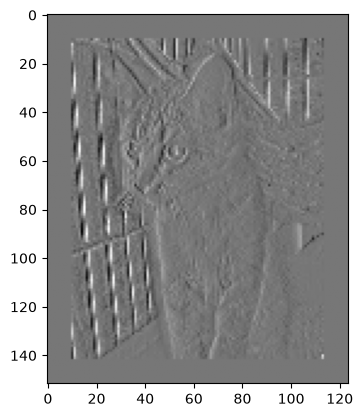

In [10]:
K = torch.tensor([
    [-1.0, 0.0, 1.0],
    [-2.0, 0.0, 2.0],
    [-1.0, 0.0, 1.0]
])
imagen = plt.imread('cat_dog_small/train/cat/cat.2.jpg').copy()
t = transforms.Compose([transforms.ToTensor(),
                        transforms.Grayscale(),
                        transforms.Lambda(lambda x:x.squeeze())])
print(imagen.shape)
imagen = t(imagen)
plt.imshow(imagen.numpy(), cmap='gray')

convol = convolution(imagen, K, 30, 3)

plt.imshow(convol.numpy(), cmap='gray')
print(convol.shape)

## Learning kernels

Once you have an efficient convolution implementation, the next step is to create a **trainable convolution module**. To do that, implement a class called `MyConv2D` that inherits from `nn.Module`.

The constructor should receive the **kernel size**, the **padding amount**, and the **stride**. Initialize a **trainable kernel** of the given size (no bias is needed). In the forward, make use of the implemented convolution.

Your goal is to use this module to **learn a kernel from data**. You will have to take an **input image** and a **target image**, which is the result of convolving the input image with a known kernel. Then, you will **train the kernel inside `MyConv2D`** so that, when convolving the input image, the output closely matches the target image. The trainable kernel should eventually approximate the original kernel used to generate the target image.



In [11]:
class MyConv2D(nn.Module):
    def __init__(self, kernel_size, padding=0, stride=1):
        super().__init__()
        
        self.padding = padding
        self.stride = stride
        
        if isinstance(kernel_size, int):
            kernel_size = (kernel_size, kernel_size)
            
        self.kernel = nn.Parameter(torch.randn(kernel_size))

    def forward(self, X):
        K = self.kernel.to(dtype=X.dtype)
        
        # Expandir dimensiones a 4D para torch.nn.functional.conv2d
        X_4d = X.unsqueeze(0).unsqueeze(0)  # (1, 1, n_h, n_w)
        K_4d = K.unsqueeze(0).unsqueeze(0)  # (1, 1, k_h, k_w)

        # Aplicar la convolución
        out_4d = f.conv2d(X_4d, K_4d, padding=self.padding, stride=self.stride)

        # Retornar en 2D (out_h, out_w)
        return out_4d.squeeze(0).squeeze(0)

## nn.Conv2d

What we have implemented with `MyConv2D` is essentially the same functionality that **`nn.Conv2d`**. This class defines a **trainable convolutional layer**, where the kernels are automatically initialized and updated during training.

The key parameters of `nn.Conv2d` are:

- **in_channels**: the number of channels in the input image. For a grayscale image, this is 1; for an RGB image, it is 3.
- **out_channels**: the number of output feature maps (i.e., how many separate kernels the layer should learn). Each kernel produces one output channel.
- **kernel_size**: the size of each convolutional kernel. Usually,  a single integer for a square kernel.
- **stride**: the step size for moving the kernel over the input.
- **padding**: the number of zeros added to the input edges. Usually, an integer  for applying same padding for all sides. Padding alse offers two alias, called padding = 'valid', which is the same as no padding; and padding = 'same', that pads the input so the output has the shape as the input.  
- **bias**: whether the layer includes an additive bias term for each output channel (optional).


## Pooling layers

In the same way as with nn.Conv2d and nn.functional.conv2d, the pooling layers can be also implemented in different ways.

The first one will by by using `nn.MaxPool2d` or `nn.AvgPool2d`. This defines a layer as part of the model, which can be used directly in the `forward` method.


In [12]:
x = torch.randn(1, 1, 4, 4)

In [13]:
pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

#Later in the forward
x = pool(x)

Los parámetros más importantes de estas capas son:
- **kernel_size**: size of the pooling window
- **stride**: step of the window (default to kernel_size).

La segunda forma de hacerlo es mediante nn.functional.max_pool2d o avg_pool2d. Here, the pooling is applied directly to a tensor, with creating the layer object.

In [14]:
x = torch.nn.functional.max_pool2d(x, kernel_size=2, stride=2, padding=0)

### MNIST Fashion with feature extraction

In this exercise, you will extend a simple MLP for image classification by **adding a convolutional feature extraction stage** using `nn.Conv2d`. The goal is to automatically learn useful features from the images before passing them to a fully connected classifier. The steps are:

1. **Convolutional Layer**

   * Create a convolutional layer with a configurable number of output channels (filters).
   * Apply **ReLU** after the convolution.

2. **Downsampling**

   * Use **MaxPool2d** to reduce the size of the feature maps.

3. **Flattening**

   * Flatten the feature maps into a 1D vector to serve as input for the MLP.

4. **MLP Classification**

   * Pass the flattened vector through a **hidden layer** (e.g., 128 neurons).
   * Then pass it through an **output layer** for classification (number of classes).

For doing this, implement a class **`MLPWithConv`**. The constructor should receive at least `output_channels` (number of convolutional filters). The `forward` method should execute the full pipeline: **convolution → ReLU → max pooling → flatten → fully connected layers**.

This design allows the network to learn features automatically from the images and then classify them using a traditional MLP. Trainable end-to-end, this illustrates how convolutional layers integrate with fully connected layers in modern neural networks.

Once the model is implemented, load the Fashion-MNIST dataset (provide the code to create the dataset and dataloader) and train a network with these characteristics. Compare the results with the MLP from assignment `05_MLP_04`. Aspects to analyze:
* How the number of kernels in the `Conv2D` layer and the kernel size affect performance.
* How the MLP part affects performance. Is it necessary to add more hidden layers? Is it necessary to add regularization between layers?
* You should also visualize the types of kernels learned or the images generated by `nn.Conv2d`.





You can use the data provided in MiAulario or download from torchvision.

In [15]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Opcional: escala los valores de [0, 1] a [-1, 1]
])

In [16]:
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [17]:
class MLPWithConv(nn.Module):
    def __init__(self, output_channels=32, kernel_size=3, num_classes=10, hidden_dim=128):
        super().__init__()
        
        padding = kernel_size // 2
        
        # 1. Capa convolucional
        self.conv = nn.Conv2d(
            in_channels=1, 
            out_channels=output_channels, 
            kernel_size=kernel_size, 
            padding=padding
        )
        self.relu = nn.ReLU()
        
        # 2. Downsampling (MaxPool2d reduce 28x28 a 14x14)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # 3 y 4. Clasificador MLP
        flatten_dim = output_channels * 14 * 14
        self.fc1 = nn.Linear(flatten_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # 1. Conv + ReLU
        x = self.conv(x)
        x = self.relu(x)
        
        # 2. Max Pooling
        x = self.pool(x)
        
        # 3. Flatten (Aplanar a 1D por muestra)
        x = x.view(x.size(0), -1)  # (batch_size, output_channels * 14 * 14)
        
        # 4. MLP Classification
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        
        return x

In [18]:
import torch.optim as optim

# Configurar dispositivo (GPU si está disponible, sino CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instanciar el modelo, función de pérdida y optimizador
model = MLPWithConv(output_channels=32, kernel_size=3, hidden_dim=128).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5

for epoch in range(epochs):
    # Fase de Entrenamiento
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    # Fase de Evaluación en Test
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
    acc = 100 * correct / total
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {running_loss/len(train_loader):.4f} - Test Accuracy: {acc:.2f}%")

Epoch 1/5 - Train Loss: 0.4248 - Test Accuracy: 88.25%
Epoch 2/5 - Train Loss: 0.2865 - Test Accuracy: 87.96%
Epoch 3/5 - Train Loss: 0.2385 - Test Accuracy: 90.01%
Epoch 4/5 - Train Loss: 0.2078 - Test Accuracy: 89.60%
Epoch 5/5 - Train Loss: 0.1827 - Test Accuracy: 90.31%


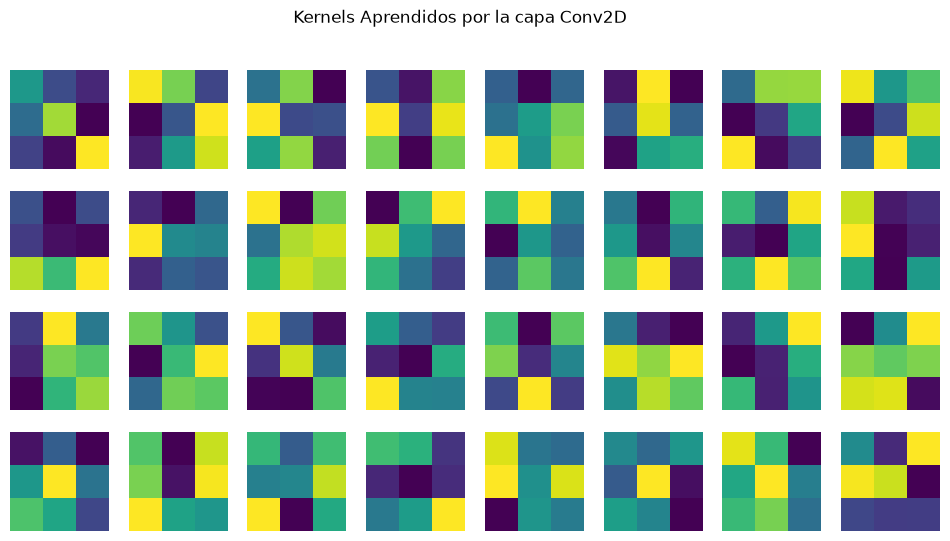

In [19]:
import matplotlib.pyplot as plt

# Obtener los pesos de la capa convolucional: forma (32, 1, 3, 3)
kernels = model.conv.weight.data.cpu()

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < kernels.shape[0]:
        # Visualizar cada filtro de 3x3
        ax.imshow(kernels[i, 0], cmap='viridis')
        ax.axis('off')
plt.suptitle('Kernels Aprendidos por la capa Conv2D')
plt.show()

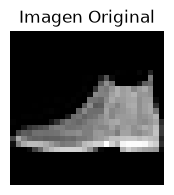

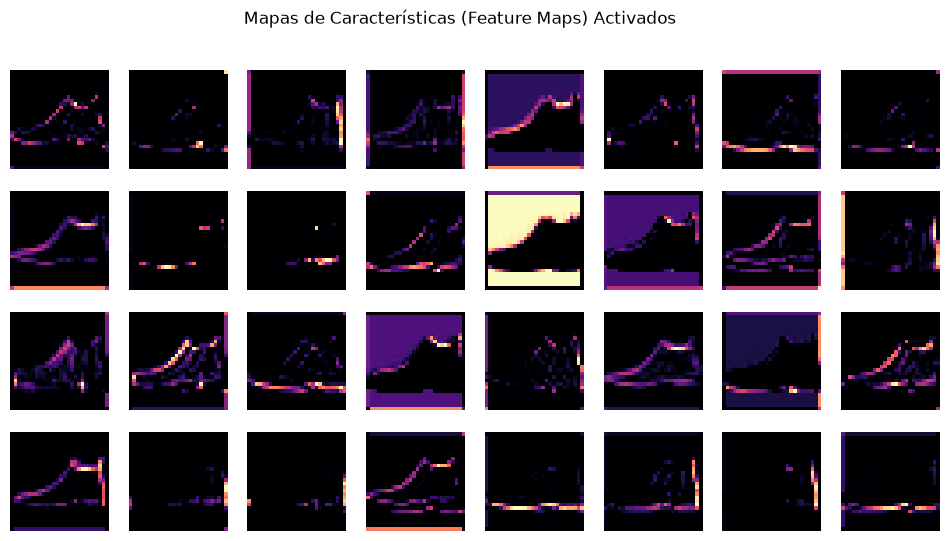

In [20]:
# Tomar una imagen del conjunto de test
sample_img, sample_label = test_dataset[0]
sample_input = sample_img.unsqueeze(0).to(device) # (1, 1, 28, 28)

model.eval()
with torch.no_grad():
    # Obtener las activaciones tras la convolución + ReLU
    fmaps = model.relu(model.conv(sample_input)).cpu().squeeze(0) # (32, 28, 28)

# Graficar la imagen original
plt.figure(figsize=(2, 2))
plt.imshow(sample_img.squeeze(0), cmap='gray')
plt.title("Imagen Original")
plt.axis('off')
plt.show()

# Graficar los 32 mapas de características generados
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < fmaps.shape[0]:
        ax.imshow(fmaps[i], cmap='magma')
        ax.axis('off')
plt.suptitle('Mapas de Características (Feature Maps) Activados')
plt.show()